# AlertaBairro — Rota de menor risco (Programação Dinâmica)

**GS CitizenTech 2026.2 · Engenharia de Software · FIAP**

**Integrantes:** `[nome completo — RM]` · `[nome completo — RM]` · `[nome completo — RM]`

## Problema

Durante alagamentos, os moradores precisam ir de um ponto a outro do bairro (ex.: de casa até um posto de saúde ou escola) **evitando os trechos com maior risco de alagamento**. Este notebook calcula, por Programação Dinâmica, a rota de **menor risco acumulado** entre dois pontos do bairro, representando a região como uma grade de quarteirões.

## Fonte dos dados

A grade de risco é derivada da mesma base usada no entregável de Data Science (`dados_ocorrencias_alertabairro.csv`): latitude e longitude de cada ocorrência são agrupadas em uma grade 6x6, e o risco de cada célula combina a **quantidade** de ocorrências registradas e a **gravidade média** nelas. Células sem ocorrência registrada recebem risco mínimo (1). Isso conecta este entregável diretamente à análise feita em Data Science.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../dados_ocorrencias_alertabairro.csv")

ROWS, COLS = 6, 6
grav_num = {"Baixa": 1, "Média": 2, "Alta": 3}
df["gravidade_num"] = df["gravidade"].map(grav_num)

lat_bins = np.linspace(df["latitude"].min(), df["latitude"].max(), ROWS + 1)
lon_bins = np.linspace(df["longitude"].min(), df["longitude"].max(), COLS + 1)
df["lin"] = np.clip(np.digitize(df["latitude"], lat_bins) - 1, 0, ROWS - 1)
df["col"] = np.clip(np.digitize(df["longitude"], lon_bins) - 1, 0, COLS - 1)

def montar_grid(sub_df, rows=ROWS, cols=COLS):
    """Agrega ocorrências em uma grade rows x cols; risco de 1 (baixo) a 10 (alto)."""
    agg = sub_df.groupby(["lin", "col"]).agg(
        qtd=("id_ocorrencia", "count"),
        grav_media=("gravidade_num", "mean")
    ).reset_index()
    grid = [[1 for _ in range(cols)] for _ in range(rows)]
    if len(agg) == 0:
        return grid
    max_qtd = agg["qtd"].max()
    for _, r in agg.iterrows():
        densidade = r["qtd"] / max_qtd           # 0 a 1
        grav_norm = (r["grav_media"] - 1) / 2     # 0 a 1
        risco = 1 + round(5 * densidade + 4 * grav_norm)
        grid[int(r["lin"])][int(r["col"])] = int(min(10, max(1, risco)))
    return grid

grid = montar_grid(df)
print("Grade de risco do bairro (linha 0 = topo):")
for linha in grid:
    print(linha)


Grade de risco do bairro (linha 0 = topo):
[1, 1, 1, 1, 4, 6]
[4, 3, 1, 1, 4, 4]
[7, 6, 2, 1, 1, 1]
[3, 4, 8, 7, 1, 1]
[1, 1, 4, 5, 2, 1]
[1, 1, 3, 5, 3, 1]


## Modelagem

- **Estado:** `dp[i][j]` = menor risco acumulado para chegar ao quarteirão `(i, j)` partindo do quarteirão `(0, 0)`.
- **Movimentos permitidos:** apenas para a **direita** ou para **baixo** — simplificação razoável para quem está seguindo em direção a um destino, sem voltar para trás.
- **Recorrência:**

```
dp[0][0] = grid[0][0]
dp[0][j] = dp[0][j-1] + grid[0][j]          (só dá pra vir da esquerda, na primeira linha)
dp[i][0] = dp[i-1][0] + grid[i][0]          (só dá pra vir de cima, na primeira coluna)
dp[i][j] = grid[i][j] + min(dp[i-1][j], dp[i][j-1])   (caso geral)
```

A resposta final é `dp[rows-1][cols-1]`: o menor risco acumulado para atravessar o bairro inteiro, da origem (ex.: casa do morador) até o destino (ex.: posto de saúde). Guardamos também, em `origem[i][j]`, de qual célula veio o melhor caminho até `(i, j)`, para reconstruir a rota no final.


In [2]:
def menor_caminho_risco(grid):
    """Programação dinâmica (tabulação): menor risco acumulado de (0,0) até
    (rows-1, cols-1), movendo-se apenas para a direita ou para baixo.
    Retorna o risco total e a lista de células do caminho."""
    rows, cols = len(grid), len(grid[0])
    dp = [[0] * cols for _ in range(rows)]
    origem = [[None] * cols for _ in range(rows)]

    dp[0][0] = grid[0][0]
    for j in range(1, cols):
        dp[0][j] = dp[0][j - 1] + grid[0][j]
        origem[0][j] = (0, j - 1)
    for i in range(1, rows):
        dp[i][0] = dp[i - 1][0] + grid[i][0]
        origem[i][0] = (i - 1, 0)

    for i in range(1, rows):
        for j in range(1, cols):
            if dp[i - 1][j] <= dp[i][j - 1]:
                dp[i][j] = dp[i - 1][j] + grid[i][j]
                origem[i][j] = (i - 1, j)
            else:
                dp[i][j] = dp[i][j - 1] + grid[i][j]
                origem[i][j] = (i, j - 1)

    # reconstrói o caminho a partir do destino
    caminho = []
    i, j = rows - 1, cols - 1
    while (i, j) != (0, 0):
        caminho.append((i, j))
        i, j = origem[i][j]
    caminho.append((0, 0))
    caminho.reverse()
    return dp[rows - 1][cols - 1], caminho


## Exemplo: rota real do bairro simulado

Origem = `(0,0)` (quarteirão do morador) · Destino = `(5,5)` (posto de saúde/UBS).

Risco total da rota: 11
Caminho (linha, coluna): [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (2, 4), (2, 5), (3, 5), (4, 5), (5, 5)]


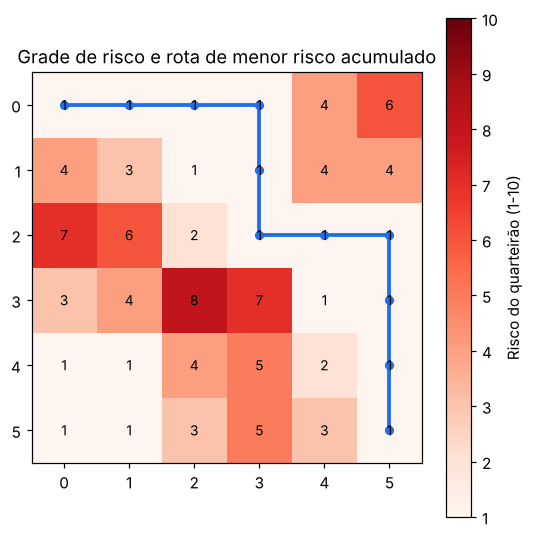

In [3]:
risco_total, caminho = menor_caminho_risco(grid)
print("Risco total da rota:", risco_total)
print("Caminho (linha, coluna):", caminho)

fig, ax = plt.subplots(figsize=(5, 5))
matriz = np.array(grid)
im = ax.imshow(matriz, cmap="Reds", vmin=1, vmax=10)
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        ax.text(j, i, matriz[i, j], ha="center", va="center", fontsize=9)

ys, xs = zip(*caminho)
ax.plot(xs, ys, color="#1f6feb", linewidth=2.5, marker="o", markersize=5)
ax.set_title("Grade de risco e rota de menor risco acumulado")
ax.set_xticks(range(6)); ax.set_yticks(range(6))
plt.colorbar(im, label="Risco do quarteirão (1-10)")
plt.tight_layout()
plt.show()


## Testes e demonstração

### Teste 1 — grade pequena com resultado conhecido

Valida a implementação com uma grade 3x3 cujo caminho de menor risco pode ser conferido manualmente.

In [4]:
grid_teste = [
    [1, 1, 5],
    [9, 1, 1],
    [9, 9, 1],
]
# Caminho manualmente verificável: (0,0)->(0,1)->(1,1)->(1,2)->(2,2) = 1+1+1+1+1 = 5
risco_teste, caminho_teste = menor_caminho_risco(grid_teste)
print("Risco obtido:", risco_teste, "| Caminho:", caminho_teste)
assert risco_teste == 5, "o algoritmo não encontrou o menor risco esperado"
print("OK: o algoritmo encontrou o menor risco esperado.")


Risco obtido: 5 | Caminho: [(0, 0), (0, 1), (1, 1), (1, 2), (2, 2)]
OK: o algoritmo encontrou o menor risco esperado.


### Teste 2 — a rota se adapta quando um trecho antes seguro alaga

Simula um alagamento repentino exatamente no trecho que, no exemplo real acima, fazia parte da rota mais segura. O algoritmo precisa recalcular e indicar um desvio.

In [5]:
import copy

grid_alagado = copy.deepcopy(grid)
grid_alagado[1][3] = 8   # bueiro transbordou neste quarteirão
grid_alagado[2][3] = 9   # rua alagada logo abaixo

risco_novo, caminho_novo = menor_caminho_risco(grid_alagado)

print("Caminho original  :", caminho, "| risco:", risco_total)
print("Caminho após alagar:", caminho_novo, "| risco:", risco_novo)
print("A rota mudou?", caminho_novo != caminho)


Caminho original  : [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (2, 4), (2, 5), (3, 5), (4, 5), (5, 5)] | risco: 11
Caminho após alagar: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (2, 5), (3, 5), (4, 5), (5, 5)] | risco: 17
A rota mudou? True


## Algoritmo e complexidade

- **Técnica:** Programação Dinâmica por **tabulação** (bottom-up): cada célula `dp[i][j]` é calculada uma única vez, reaproveitando os resultados já prontos de `dp[i-1][j]` e `dp[i][j-1]` — não há recomputação de subproblemas.
- **Complexidade de tempo:** O(linhas × colunas), pois cada célula é visitada e calculada em tempo O(1).
- **Complexidade de espaço:** O(linhas × colunas) para guardar `dp` e `origem` (poderia cair para O(colunas) se não precisássemos reconstruir o caminho, guardando só a linha anterior).
- **Por que DP e não busca por força bruta:** o número de caminhos possíveis cresce exponencialmente com o tamanho da grade; a tabulação resolve cada quarteirão apenas uma vez, tornando o cálculo viável mesmo numa grade maior (bairro inteiro).

O Teste 2 mostra exatamente o cenário de uso real do AlertaBairro: quando novas ocorrências de alagamento são registradas pelos moradores (módulo de registro), a grade de risco é atualizada e o algoritmo recalcula a rota mais segura automaticamente — sem precisar reprogramar nada, só recalcular a tabela `dp` com os novos valores de risco.